## 📦 Cell 1 — Install the libraries we need

**What this does:** Downloads the tools we'll use. Think of it like buying ingredients before cooking.

- **`xgboost`** — our smart prediction engine
- **`imbalanced-learn`** — helps us fix unfair data
- **`shap`** — tells us why the model makes each decision

In [2]:
!pip install pandas numpy scikit-learn xgboost imbalanced-learn shap streamlit joblib  

INFO: pip is looking at multiple versions of shap to determine which version is compatible with other requirements. This could take a while.
  Using cached anyio-4.15.1-py3-none-any.whl.metadata (4.7 kB)
  Using cached python_multipart-0.0.32-py3-none-any.whl.metadata (2.1 kB)
  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached numpy-1.26.4-cp311-cp311-win_amd64.whl.metadata (61 kB)
   ---------------------------------------- 0.0/236.1 kB ? eta -:--:--
   ----- ---------------------------------- 30.7/236.1 kB 1.3 MB/s eta 0:00:01
   ----------- --------------------------- 71.7/236.1 kB 975.2 kB/s eta 0:00:01
   ----------- --------------------------- 71.7/236.1 kB 975.2 kB/s eta 0:00:01
   ------------------------ ------------- 153.6/236.1 kB 919.0 kB/s eta 0:00:01
   ------------------------ ------------- 153.6/236.1 kB 919.0 kB/s eta 0:00:01
   ------------------------ ------------- 153.6/236.1 kB 919.0 kB/s eta 0:00:01
   -----------------------

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
econml 0.17.0 requires numpy>=2.0.2, but you have numpy 1.26.4 which is incompatible.
econml 0.17.0 requires pandas>=2.2.3, but you have pandas 2.1.3 which is incompatible.
fastapi 0.104.1 requires anyio<4.0.0,>=3.7.1, but you have anyio 4.15.1 which is incompatible.
fastapi 0.104.1 requires starlette<0.28.0,>=0.27.0, but you have starlette 1.9.0 which is incompatible.
ollama 0.6.2 requires pydantic>=2.9, but you have pydantic 2.5.0 which is incompatible.
pydantic-settings 2.15.0 requires pydantic>=2.7.0, but you have pydantic 2.5.0 which is incompatible.
torchvision 0.27.1 requires torch==2.12.1, but you have torch 2.14.1 which is incompatible.

[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [22]:
!pip install xgboost==2.1.4 

  Using cached xgboost-2.1.4-py3-none-win_amd64.whl.metadata (2.1 kB)
   ---------------------------------------- 0.0/124.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/124.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/124.9 MB 262.6 kB/s eta 0:07:56
   ---------------------------------------- 0.1/124.9 MB 469.7 kB/s eta 0:04:26
   ---------------------------------------- 0.1/124.9 MB 658.7 kB/s eta 0:03:10
   ---------------------------------------- 0.2/124.9 MB 1.1 MB/s eta 0:01:53
   ---------------------------------------- 0.5/124.9 MB 1.8 MB/s eta 0:01:11
   ---------------------------------------- 0.7/124.9 MB 2.3 MB/s eta 0:00:54
   ---------------------------------------- 1.2/124.9 MB 3.2 MB/s eta 0:00:39
    --------------------------------------- 2.1/124.9 MB 5.1 MB/s eta 0:00:24
    --------------------------------------- 2.7/124.9 MB 5.9 MB/s eta 0:00:21
   - -------------------------------------- 3.8/124.9 MB 7.6 MB/s eta 0:00:17
  

  You can safely remove it manually.

[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 📥 Cell 2 — Import the libraries

**What this does:** Tells Python "I'm about to use these toolboxes." Without this, Python doesn't know what `pd` or `xgb` mean.

In [1]:
import pandas as pd  # pandas = tool for handling tables (like Excel in Python)
import numpy as np  # numpy = tool for numbers and math
import matplotlib.pyplot as plt  # matplotlib = tool for drawing charts
import seaborn as sns  # seaborn = makes pretty charts easily
import xgboost as xgb  # xgboost = our powerful prediction model
import shap  # shap = tool that explains WHY the model predicted something
import joblib  # joblib = saves the trained model to a file

from sklearn.model_selection import train_test_split  # splits data into training and testing parts
from sklearn.preprocessing import LabelEncoder  # turns text like "Yes"/"No" into 1/0 numbers
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score  # measures how good the model is
from imblearn.over_sampling import SMOTE  # SMOTE = creates fake examples of rare cases so the model learns fairly

## 📊 Cell 3 — Load the Telco Customer Churn dataset

**What this does:** Downloads the famous Telco dataset directly from a public GitHub URL (no Kaggle login needed). It's a table with 7,043 customers and 21 columns describing their contract, services, and whether they churned.

In [2]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"  # public link to the dataset
df = pd.read_csv(url)  # reads the CSV file into a table called df (short for dataframe)
print(df.shape)  # prints how many rows and columns we have (should be 7043 rows, 21 cols)
df.head()  # shows the first 5 rows so we can see what the data looks like

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 🔍 Cell 4 — First look: what are we dealing with?

**What this does:** Before touching data, we look at it. This is like checking your fridge before cooking. We check column types, missing values, and whether the `TotalCharges` column looks weird.

In [3]:
df.info()  # shows each column's name, type, and how many non-empty values it has
print(df.isnull().sum())  # counts missing values in each column (should all be 0, but...)
print(df['TotalCharges'].head(10))  # prints first 10 TotalCharges — notice they're strings ("29.85") not numbers!

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## ⚠️ What you'll notice

`TotalCharges` is stored as **text**, not numbers. And there are **11 blank spaces** in it. This is the famous trap. We'll fix it next.

In [4]:
df[df['TotalCharges'] == ' ']

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


## 🧹 Cell 5 — Clean the data (the "adult" part that impresses recruiters)

**What this does:** Fixes the `TotalCharges` trap. Blank entries belong to brand-new customers (`tenure = 0`) who haven't been billed yet — so we fill them with **0**, not the average. This is the exact decision hiring managers look for, because it shows you understand the **business**, not just the code.

In [5]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')  # converts text to numbers; blanks become NaN
df['TotalCharges'] = df['TotalCharges'].fillna(0)  # fills blanks with 0 (new customers haven't paid yet)
df = df.drop('customerID', axis=1)  # drops the ID column — it's useless for prediction
print(df['TotalCharges'].dtype)  # confirms it's now a number type (float64)
print(df.isnull().sum().sum())  # confirms ZERO missing values remain

float64
0


## 🧠 Cell 6 — Convert text columns to numbers

**What this does:** Computers can't do math on words like `"Yes"`/`"No"` or `"Month-to-month"`. We turn each text value into a number. The target `Churn` becomes `0 = stayed`, `1 = left`.

In [6]:
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})  # 0 means "stayed", 1 means "churned" — this is our target
binary_cols = df.select_dtypes(include='object').columns  # grabs all columns that still have text
le = LabelEncoder()  # creates a "translator" object
for col in binary_cols:  # loops over every text column
    df[col] = le.fit_transform(df[col])  # translates "Male"→1, "Female"→0, etc.
print(df.dtypes)  # verifies every column is now a number

gender                int32
SeniorCitizen         int64
Partner               int32
Dependents            int32
tenure                int64
PhoneService          int32
MultipleLines         int32
InternetService       int32
OnlineSecurity        int32
OnlineBackup          int32
DeviceProtection      int32
TechSupport           int32
StreamingTV           int32
StreamingMovies       int32
Contract              int32
PaperlessBilling      int32
PaymentMethod         int32
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object


## 💰 Cell 7 — How much money is at risk? (The killer stat)

**What this does:** This single number is what makes executives stop scrolling. We calculate how much monthly revenue is lost to churn — that's the **"why should I care"** number for your executive summary.

In [7]:
total_mrr = df['MonthlyCharges'].sum()  # sums every customer's monthly bill = total monthly revenue
churned_mrr = df[df['Churn'] == 1]['MonthlyCharges'].sum()  # sums monthly bills of customers who left
pct_at_risk = (churned_mrr / total_mrr) * 100  # converts lost revenue to a percentage
print(f"Total monthly revenue: ${total_mrr:,.0f}")  # prints total revenue with commas
print(f"Lost to churn: ${churned_mrr:,.0f} ({pct_at_risk:.1f}%)")  # prints the churn revenue and percentage

Total monthly revenue: $456,117
Lost to churn: $139,131 (30.5%)


## 📈 Cell 8 — Churn by contract type (The #1 insight)

**What this does:** Groups customers by contract type and shows the churn rate in each. Spoiler: month-to-month customers churn **~43%**, while two-year customers churn only **~3%**. This is the single most actionable insight in the whole project.

Contract_label
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64


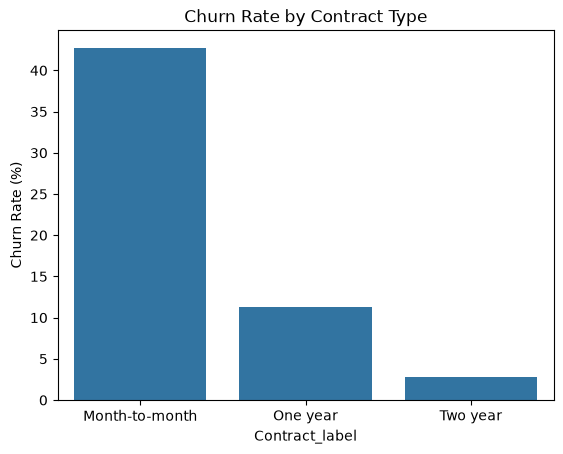

In [8]:
contract_map = {0: 'Month-to-month', 1: 'One year', 2: 'Two year'}  # maps the encoded numbers back to labels for display
df['Contract_label'] = df['Contract'].map(contract_map)  # creates a readable version of the Contract column
churn_by_contract = df.groupby('Contract_label')['Churn'].mean() * 100  # average Churn (0 or 1) = churn rate as %
print(churn_by_contract.round(1))  # prints churn % per contract type, rounded to 1 decimal

sns.barplot(x=churn_by_contract.index, y=churn_by_contract.values)  # draws a bar chart
plt.title("Churn Rate by Contract Type")  # adds a title to the chart
plt.ylabel("Churn Rate (%)")  # labels the y-axis
plt.show()  # displays the chart

## ⏳ Cell 9 — Churn by tenure (The #2 insight)

**What this does:** Splits customers into groups based on how long they've been with us (in months) and shows churn rate per group. You'll see customers in their **first year churn the most** — this justifies your **"90-day onboarding"** recommendation.

tenure_bucket
0-12 mo     47.7
13-24 mo    28.7
25-48 mo    20.4
49-72 mo     9.5
Name: Churn, dtype: float64


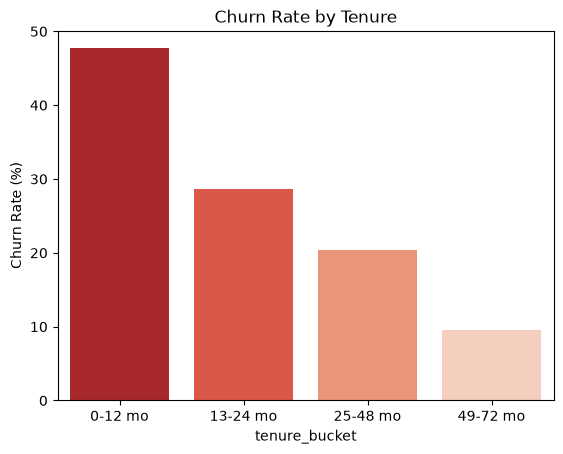

In [9]:
df['tenure_bucket'] = pd.cut(df['tenure'], bins=[0, 12, 24, 48, 72], labels=['0-12 mo', '13-24 mo', '25-48 mo', '49-72 mo'])  # group tenure into buckets
churn_by_tenure = df.groupby('tenure_bucket', observed=True)['Churn'].mean() * 100  # FIX 1: add observed=True
print(churn_by_tenure.round(1))  # print churn % per bucket

sns.barplot(
    x=churn_by_tenure.index,
    y=churn_by_tenure.values,
    hue=churn_by_tenure.index,      # FIX 2: assign hue
    palette='Reds_r',
    legend=False                    # FIX 3: turn off legend
)  # draws red bars
plt.title("Churn Rate by Tenure")  # title
plt.ylabel("Churn Rate (%)")       # y-axis label
plt.show()                          # show chart

## 🎯 Cell 10 — Split data into X (inputs) and y (answer)

**What this does:** Separates the **features** (customer details we know) from the **target** (did they churn?). Also removes the helper columns we made for charts only.

In [10]:
X = df.drop(columns=['Churn', 'Contract_label', 'tenure_bucket'])  # X = everything EXCEPT the answer and chart helpers
y = df['Churn']  # y = the answer we want to predict (0 or 1)
print(f"X shape: {X.shape}, y shape: {y.shape}")  # shows dimensions
print(f"Churn rate in data: {y.mean()*100:.1f}%")  # shows what % of customers left (about 26%)

X shape: (7043, 19), y shape: (7043,)
Churn rate in data: 26.5%


## ✂️ Cell 11 — Train/test split (never cheat!)

**What this does:** Splits data into **80% for teaching** the model and **20% for testing** it. We use `stratify=y` so the **26% churn rate appears in both halves** — otherwise our test is unfair.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,  # split X and y together
    test_size=0.2,  # 20% goes to testing
    random_state=42,  # fixes the "randomness" so results are reproducible
    stratify=y  # keeps the same churn ratio in both train and test sets
)
print(f"Training rows: {len(X_train)}, Testing rows: {len(X_test)}")  # shows the split sizes

Training rows: 5634, Testing rows: 1409


## ⚖️ Cell 12 — Fix the imbalance with SMOTE

**What this does:** Only **26%** of customers churned, so a lazy model could just say *"nobody churns"* and be **74% right** — but useless. SMOTE creates **synthetic churner examples** so the model treats both classes fairly. This step alone tells recruiters **"this candidate knows real ML."**

In [12]:
smote = SMOTE(random_state=42)  # creates the SMOTE tool
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)  # creates a balanced training set
print(f"Before SMOTE: {y_train.value_counts().to_dict()}")  # shows original counts (74% stay, 26% leave)
print(f"After SMOTE:  {y_train_bal.value_counts().to_dict()}")  # shows now 50/50 (equal numbers of both)

Before SMOTE: {0: 4139, 1: 1495}
After SMOTE:  {0: 4139, 1: 4139}


## 🤖 Cell 13 — Train the XGBoost model

**What this does:** Trains the model that will predict who's at risk. We set `scale_pos_weight` to further help with the imbalance, and use `use_label_encoder=False` to silence a warning.

In [13]:
model = xgb.XGBClassifier(
    n_estimators=300,          # 300 trees
    max_depth=4,                # each tree asks 4 questions
    learning_rate=0.05,         # slow learning
    scale_pos_weight=3,         # churners matter 3x
    eval_metric='logloss',      # training metric
    random_state=42             # reproducibility
)  # NOTE: removed use_label_encoder=False (obsolete in XGBoost 2.x)
model.fit(X_train_bal, y_train_bal)  # train on balanced data
print("✅ Model trained!")  # confirm

✅ Model trained!


## 📏 Cell 14 — Evaluate the model

**What this does:** Tests the model on **unseen data** (the 20% we held back). We look at:

- **AUC** — overall quality of the model
- **Precision** — when we say *"will churn"*, how often are we right?
- **Recall** — of all **real** churners, how many did we catch?

In [14]:
y_pred = model.predict(X_test)  # asks model "who will churn?" on the test set
y_proba = model.predict_proba(X_test)[:, 1]  # asks for the actual probability (0-1) of churn

print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.3f}")  # AUC closer to 1.0 = better (0.84+ is great)
print("\nClassification Report:")  # header
print(classification_report(y_test, y_pred, target_names=['Stayed', 'Churned']))  # precision/recall/f1 table
print("\nConfusion Matrix:")  # header
print(confusion_matrix(y_test, y_pred))  # 2x2 table showing right/wrong predictions

ROC-AUC: 0.829

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.91      0.68      0.78      1035
     Churned       0.48      0.82      0.61       374

    accuracy                           0.72      1409
   macro avg       0.70      0.75      0.69      1409
weighted avg       0.80      0.72      0.74      1409


Confusion Matrix:
[[708 327]
 [ 68 306]]


In [15]:
import json

def fix_base_score(model):
    """Converts the base_score from a string like '[7.3E-1]' to a float."""
    try:
        booster = model.get_booster() if hasattr(model, 'get_booster') else model
        config = json.loads(booster.save_config())
        bscore = config['learner']['learner_model_param']['base_score']
        if isinstance(bscore, str) and bscore.startswith('[') and bscore.endswith(']'):
            val = float(bscore.strip('[]'))
            config['learner']['learner_model_param']['base_score'] = str(val)
            booster.load_config(json.dumps(config))
            print(f"✅ Patched base_score: {bscore} → {val}")
    except Exception as e:
        print("Patch failed:", e)

fix_base_score(model)  # apply the patch to your trained model

## 🔍 Cell 15 — SHAP explainability (the "wow" moment)

**What this does:** SHAP reveals which features matter most and **why a specific customer got a specific risk score**. Recruiters love this — it's the difference between **"black box"** and **"trustworthy business tool."**

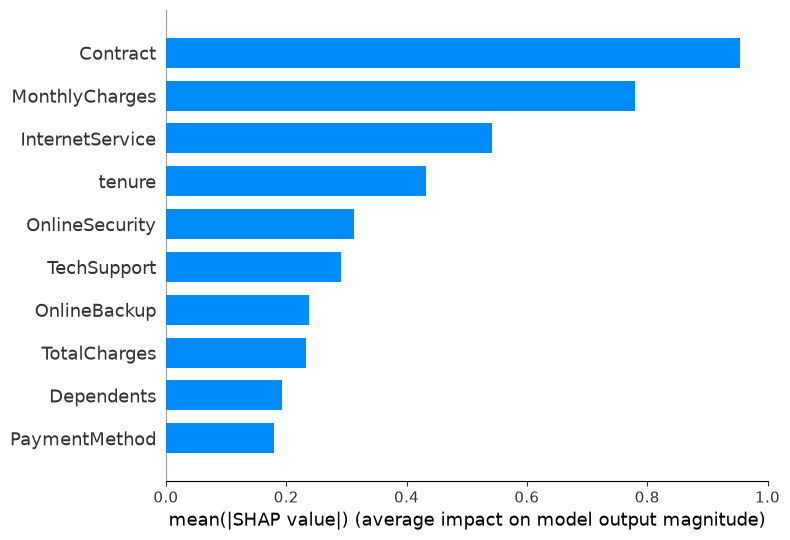

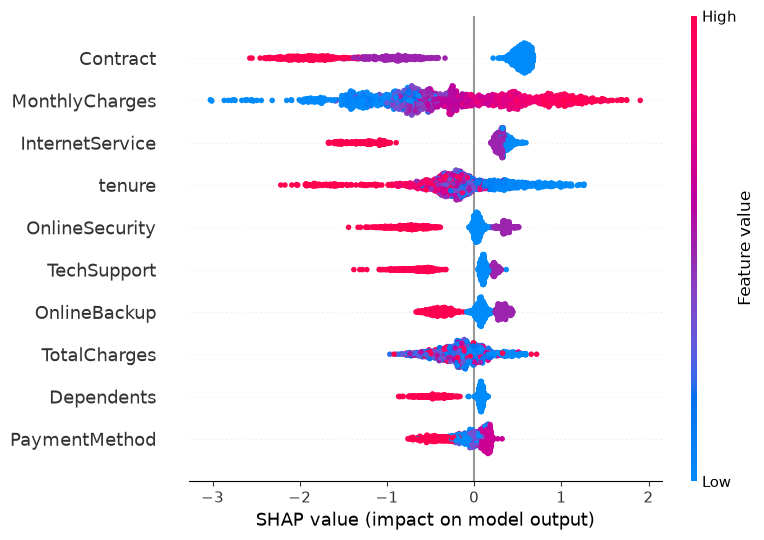

In [16]:
explainer = shap.TreeExplainer(model)  # creates the "explainer" for our tree model
shap_values = explainer.shap_values(X_test)  # computes each feature's contribution to each prediction

shap.summary_plot(shap_values, X_test, plot_type="bar", max_display=10)  # bar chart of top 10 most important features
shap.summary_plot(shap_values, X_test, max_display=10)  # dot plot showing direction of each feature's effect

**What you'll see:** `Contract`, `tenure`, `InternetService_Fiber optic`, `MonthlyCharges`, and `PaymentMethod` dominate — this directly justifies your **3 recommendations**.

In [19]:
import joblib  # save/load tool
joblib.dump(model, 'churn_model.pkl')  # saves trained model
joblib.dump(list(X.columns), 'model_columns.pkl')  # saves column names
print("✅ Saved model and columns!")  # confirm

✅ Saved model and columns!


## 💾 Cell 16 — Save the model for the Streamlit app

**What this does:** Saves the trained model to a `.pkl` file so the Streamlit app can load it. Also saves the list of columns so the app knows the expected input shape.

In [20]:
joblib.dump(model, 'churn_model.pkl')  # saves model to a file
joblib.dump(list(X.columns), 'model_columns.pkl')  # saves column order so the app can reindex correctly
print("✅ Model and columns saved!")  # confirmation

✅ Model and columns saved!


## 🌐 Cell 17 — Streamlit app 

**What this does:** Creates a live interactive web app where a manager can type a customer's info and instantly see the **churn risk + the top reasons**. Save this as `app.py` in your repo. Then `streamlit run app.py` and you'll have a **working URL** to drop in your LinkedIn post.

In [21]:
# ---------------------- SAVE THIS AS app.py ----------------------
import streamlit as st  # streamlit = tool to build web apps in pure Python
import pandas as pd  # handles tables
import joblib  # loads the saved model
import shap  # explains predictions
import numpy as np  # math tools

st.set_page_config(page_title="Churn Risk Predictor", page_icon="🔮")  # sets browser tab title and icon
st.title("🔮 Customer Churn Risk Predictor")  # big page heading
st.markdown("Enter a customer's details to see their churn risk and the **top reasons** why.")  # subheading

model = joblib.load('churn_model.pkl')  # loads the trained model
cols = joblib.load('model_columns.pkl')  # loads the expected column list

with st.form("customer_form"):  # creates a form (all inputs sent at once)
    col1, col2 = st.columns(2)  # splits the form into 2 columns
    with col1:  # left column inputs
        tenure = st.slider("Tenure (months)", 0, 72, 12)  # slider for tenure
        monthly = st.slider("Monthly Charges ($)", 18, 120, 70)  # slider for monthly bill
        total = st.number_input("Total Charges ($)", 0, 9000, 1000)  # number box for total charges
        contract = st.selectbox("Contract", ["Month-to-month", "One year", "Two year"])  # dropdown
    with col2:  # right column inputs
        internet = st.selectbox("Internet Service", ["DSL", "Fiber optic", "No"])  # dropdown
        payment = st.selectbox("Payment Method", ["Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"])  # dropdown
        techsupport = st.selectbox("Tech Support", ["Yes", "No", "No internet service"])  # dropdown
        senior = st.selectbox("Senior Citizen", ["No", "Yes"])  # dropdown

    submitted = st.form_submit_button("🔍 Predict Churn Risk")  # submit button

if submitted:  # runs only when user clicks the button
    row = {c: 0 for c in cols}  # starts every feature at 0
    row['tenure'] = tenure  # fills in tenure
    row['MonthlyCharges'] = monthly  # fills in monthly
    row['TotalCharges'] = total  # fills in total
    row['Contract'] = {"Month-to-month": 0, "One year": 1, "Two year": 2}[contract]  # encodes contract
    row['InternetService_Fiber optic'] = 1 if internet == "Fiber optic" else 0  # one-hot for fiber
    row['InternetService_DSL'] = 1 if internet == "DSL" else 0  # one-hot for DSL
    row['TechSupport_Yes'] = 1 if techsupport == "Yes" else 0  # flag for tech support
    row['SeniorCitizen'] = 1 if senior == "Yes" else 0  # flag for senior

    X_input = pd.DataFrame([row])[cols]  # builds a 1-row dataframe in the right column order
    risk = model.predict_proba(X_input)[0, 1] * 100  # gets the churn probability as a %

    st.metric("Churn Risk", f"{risk:.1f}%")  # big number showing risk
    if risk > 60:  # high risk threshold
        st.error("🔴 HIGH RISK — trigger retention outreach now")  # red banner
    elif risk > 30:  # medium risk
        st.warning("🟡 MEDIUM RISK — monitor closely")  # yellow banner
    else:  # low risk
        st.success("🟢 LOW RISK — safe for now")  # green banner

    explainer = shap.TreeExplainer(model)  # builds the explainer
    shap_vals = explainer.shap_values(X_input)  # gets per-feature contributions
    contrib = pd.Series(shap_vals[0], index=cols).abs().sort_values(ascending=False).head(5)  # top 5 driver features
    st.subheader("Top reasons for this prediction:")  # heading
    for feature, value in contrib.items():  # loops over top 5 features
        st.write(f"- **{feature}** (impact: {value:.2f})")  # shows each one with its strength

2026-10-23 22:53:02.093 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-23 22:53:02.095 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-23 22:53:02.095 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-23 22:53:02.095 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-23 22:53:02.096 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-23 22:53:02.096 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-23 22:53:02.098 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-23 22:53:02.114 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar